Python: 3.13.18
NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3

Aman your Environment is ready.
Parameter model defined.
Microwave total decay rate: 1.000
Optical total decay rate: 1.000
Conversion efficiency: 0.810000
Conversion efficiency (%): 81.000%
Maximum efficiency: 0.809999
Coupling at maximum: 0.500521


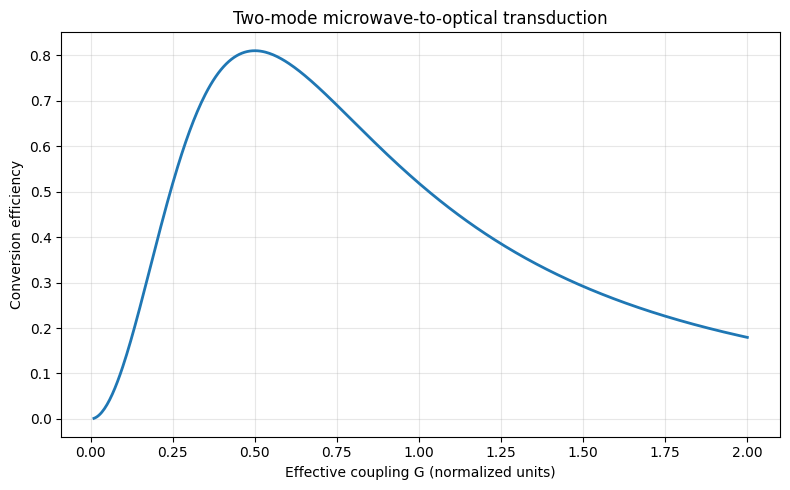

   coupling  conversion_efficiency
0  0.010000               0.001295
1  0.013988               0.002532
2  0.017976               0.004177
3  0.021964               0.006228
4  0.025952               0.008682

Saved conversion_efficiency_sweep.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
%pip install -q numpy scipy matplotlib pandas
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)

print("\nAman your Environment is ready.")

from dataclasses import dataclass


@dataclass(frozen=True)
class TransducerParameters:
    """
    Parameters for a simplified two-mode transducer.

    All rates are angular-frequency rates in rad/s.
    The numerical values used later are illustrative.
    """
    kappa_m_ext: float
    kappa_m_int: float
    kappa_o_ext: float
    kappa_o_int: float
    coupling: float
    detuning_m: float = 0.0
    detuning_o: float = 0.0

    def validate(self):
        rates = {
            "kappa_m_ext": self.kappa_m_ext,
            "kappa_m_int": self.kappa_m_int,
            "kappa_o_ext": self.kappa_o_ext,
            "kappa_o_int": self.kappa_o_int,
            "coupling": self.coupling,
        }

        for name, value in rates.items():
            if not np.isfinite(value) or value < 0:
                raise ValueError(
                    f"{name} must be finite and non-negative."
                )

        for name, value in {
            "detuning_m": self.detuning_m,
            "detuning_o": self.detuning_o,
        }.items():
            if not np.isfinite(value):
                raise ValueError(f"{name} must be finite.")

        if self.kappa_m_ext + self.kappa_m_int <= 0:
            raise ValueError("Microwave total decay rate must be positive.")

        if self.kappa_o_ext + self.kappa_o_int <= 0:
            raise ValueError("Optical total decay rate must be positive.")


print("Parameter model defined.")


def conversion_efficiency(params):
    """
    Calculate resonant-frequency conversion efficiency
    for the simplified two-mode coupled-mode model.
    """
    params.validate()

    kappa_m = params.kappa_m_ext + params.kappa_m_int
    kappa_o = params.kappa_o_ext + params.kappa_o_int
    G = params.coupling

    denominator = (
        (kappa_m / 2 - 1j * params.detuning_m)
        * (kappa_o / 2 - 1j * params.detuning_o)
        + G**2
    )

    if abs(denominator) == 0:
        raise ZeroDivisionError("The response denominator is zero.")

    numerator = params.kappa_m_ext * params.kappa_o_ext * G**2

    efficiency = numerator / abs(denominator)**2

    # Allow only tiny floating-point excursions outside [0, 1].
    if efficiency < -1e-12 or efficiency > 1 + 1e-12:
        raise ArithmeticError(
            f"Efficiency {efficiency} lies outside physical bounds."
        )

    return float(np.clip(efficiency, 0.0, 1.0))

params = TransducerParameters(
    kappa_m_ext=0.9,
    kappa_m_int=0.1,
    kappa_o_ext=0.9,
    kappa_o_int=0.1,
    coupling=0.5,
)

eta = conversion_efficiency(params)

print(f"Microwave total decay rate: "
      f"{params.kappa_m_ext + params.kappa_m_int:.3f}")

print(f"Optical total decay rate: "
      f"{params.kappa_o_ext + params.kappa_o_int:.3f}")

print(f"Conversion efficiency: {eta:.6f}")
print(f"Conversion efficiency (%): {100 * eta:.3f}%")


couplings = np.linspace(0.01, 2.0, 500)
efficiencies = []

for G in couplings:
    trial_params = TransducerParameters(
        kappa_m_ext=0.9,
        kappa_m_int=0.1,
        kappa_o_ext=0.9,
        kappa_o_int=0.1,
        coupling=G,
    )
    efficiencies.append(conversion_efficiency(trial_params))

efficiencies = np.asarray(efficiencies)

best_index = int(np.argmax(efficiencies))

print(f"Maximum efficiency: {efficiencies[best_index]:.6f}")
print(f"Coupling at maximum: {couplings[best_index]:.6f}")

plt.figure(figsize=(8, 5))
plt.plot(couplings, efficiencies, linewidth=2)
plt.xlabel("Effective coupling G (normalized units)")
plt.ylabel("Conversion efficiency")
plt.title("Two-mode microwave-to-optical transduction")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


results = pd.DataFrame({
    "coupling": couplings,
    "conversion_efficiency": efficiencies,
})

results.to_csv("conversion_efficiency_sweep.csv", index=False)

print(results.head())
print("\nSaved conversion_efficiency_sweep.csv")

from google.colab import files
files.download("conversion_efficiency_sweep.csv")

In [15]:
%pip install -q qutip

QuTiP version: 5.3.1
Quantum simulation library ready.
Quantum dynamics simulation completed.


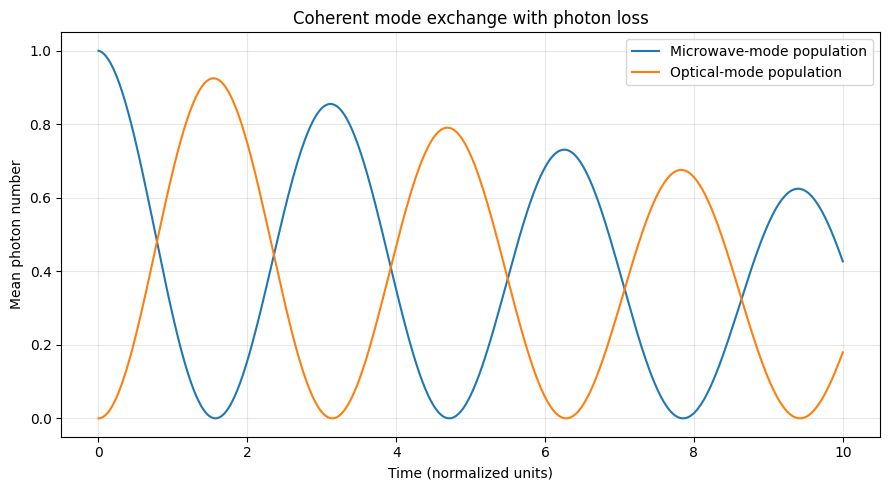

In [18]:
import qutip

print("QuTiP version:", qutip.__version__)
print("Quantum simulation library ready.")

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# Truncate each bosonic mode to the |0>, |1> states.
N_m = 2
N_o = 2

# Annihilation operators for microwave and optical modes.
a_m = qt.tensor(qt.destroy(N_m), qt.qeye(N_o))
a_o = qt.tensor(qt.qeye(N_m), qt.destroy(N_o))

# Illustrative rates in a consistent normalized unit system.
G = 1.0
kappa_m = 0.05
kappa_o = 0.05

# Effective excitation-exchange Hamiltonian, H / hbar.
H = G * (
    a_m.dag() * a_o
    + a_m * a_o.dag()
)

# Independent zero-temperature photon-loss channels.
c_ops = [
    np.sqrt(kappa_m) * a_m,
    np.sqrt(kappa_o) * a_o,
]

# Start with one microwave photon and no optical photons.
psi0 = qt.tensor(qt.basis(N_m, 1), qt.basis(N_o, 0))

# Dimensionless simulation time.
tlist = np.linspace(0, 10, 500)

# Photon-number observables.
n_m = a_m.dag() * a_m
n_o = a_o.dag() * a_o

result = qt.mesolve(
    H,
    psi0,
    tlist,
    c_ops,
    e_ops=[n_m, n_o],
)

print("Quantum dynamics simulation completed.")

plt.figure(figsize=(9, 5))

plt.plot(
    tlist,
    result.expect[0],
    label="Microwave-mode population",
)

plt.plot(
    tlist,
    result.expect[1],
    label="Optical-mode population",
)

plt.xlabel("Time (normalized units)")
plt.ylabel("Mean photon number")
plt.title("Coherent mode exchange with photon loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
n_m_values = np.asarray(result.expect[0])
n_o_values = np.asarray(result.expect[1])

total_population = n_m_values + n_o_values

assert np.all(n_m_values >= -1e-8)
assert np.all(n_o_values >= -1e-8)
assert np.all(total_population <= 1.0 + 1e-6)
assert np.isclose(n_m_values[0], 1.0, atol=1e-6)
assert np.isclose(n_o_values[0], 0.0, atol=1e-6)

print("PASS: populations are non-negative within numerical tolerance.")
print("PASS: total excitation does not exceed the initial excitation.")
print("PASS: initial state has one microwave photon and zero optical photons.")

PASS: populations are non-negative within numerical tolerance.
PASS: total excitation does not exceed the initial excitation.
PASS: initial state has one microwave photon and zero optical photons.


Thermal open-system simulation completed.


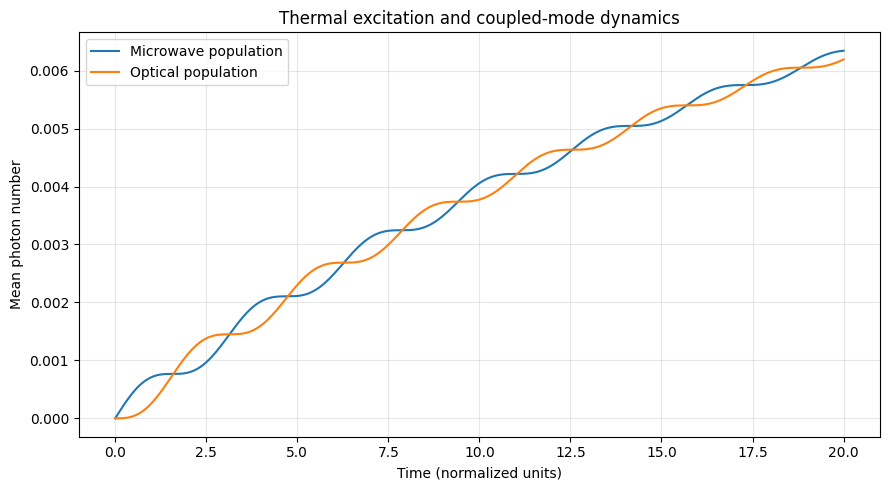

PASS: all populations are finite.
PASS: populations are non-negative within tolerance.
PASS: both modes begin in vacuum.


In [23]:
# Illustrative parameters, in normalized units.
G = 1.0
kappa_m = 0.05
kappa_o = 0.05

nbar_m = 0.02
nbar_o = 0.0

H = G * (a_m.dag() * a_o + a_m * a_o.dag())

# Thermal loss and excitation channels.
c_ops_thermal = [
    np.sqrt(kappa_m * (nbar_m + 1)) * a_m,
    np.sqrt(kappa_m * nbar_m) * a_m.dag(),
    np.sqrt(kappa_o * (nbar_o + 1)) * a_o,
]

# Begin with both modes in vacuum.
psi_vacuum = qt.tensor(
    qt.basis(N_m, 0),
    qt.basis(N_o, 0),
)

rho0 = qt.ket2dm(psi_vacuum)

tlist = np.linspace(0, 20, 1000)

result_thermal = qt.mesolve(
    H,
    rho0,
    tlist,
    c_ops_thermal,
    e_ops=[n_m, n_o],
)

print("Thermal open-system simulation completed.")

plt.figure(figsize=(9, 5))

plt.plot(
    tlist,
    result_thermal.expect[0],
    label="Microwave population",
)

plt.plot(
    tlist,
    result_thermal.expect[1],
    label="Optical population",
)

plt.xlabel("Time (normalized units)")
plt.ylabel("Mean photon number")
plt.title("Thermal excitation and coupled-mode dynamics")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

nm = np.asarray(result_thermal.expect[0])
no = np.asarray(result_thermal.expect[1])

assert np.all(np.isfinite(nm))
assert np.all(np.isfinite(no))
assert np.all(nm >= -1e-8)
assert np.all(no >= -1e-8)

assert abs(nm[0]) < 1e-8
assert abs(no[0]) < 1e-8

print("PASS: all populations are finite.")
print("PASS: populations are non-negative within tolerance.")
print("PASS: both modes begin in vacuum.")

Microwave population at final time: 0.006344
Optical population at final time:   0.006193
Microwave change over final interval: 5.441480e-04
Optical change over final interval:   2.078669e-04
Analytical microwave occupation: 0.01000625
Analytical optical occupation:   0.00999375
Numerical microwave occupation: 0.00980958
Numerical optical occupation:   0.00979729
Microwave absolute difference: 1.967e-04
Optical absolute difference:   1.965e-04
Numerical microwave occupation: 0.00980958
Numerical optical occupation:   0.00979729
Microwave absolute difference: 1.967e-04
Optical absolute difference:   1.965e-04


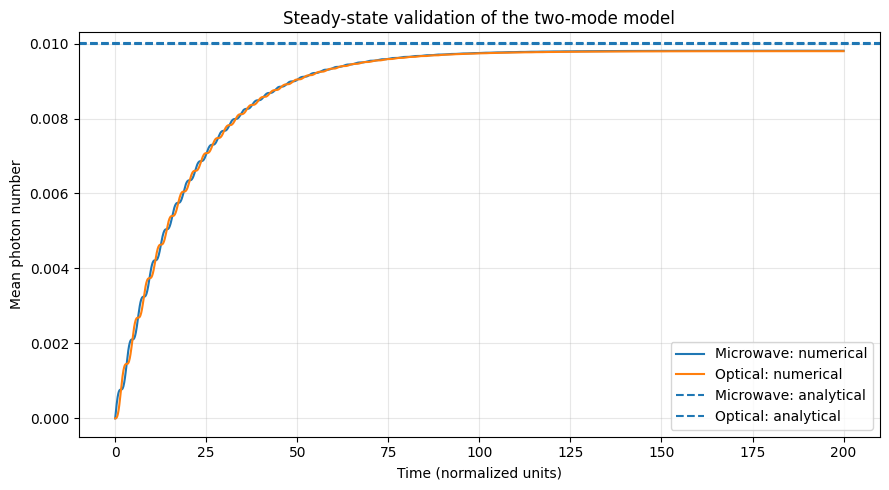

C_J: 3.545455
Efficiency at C=0.38: 0.130848


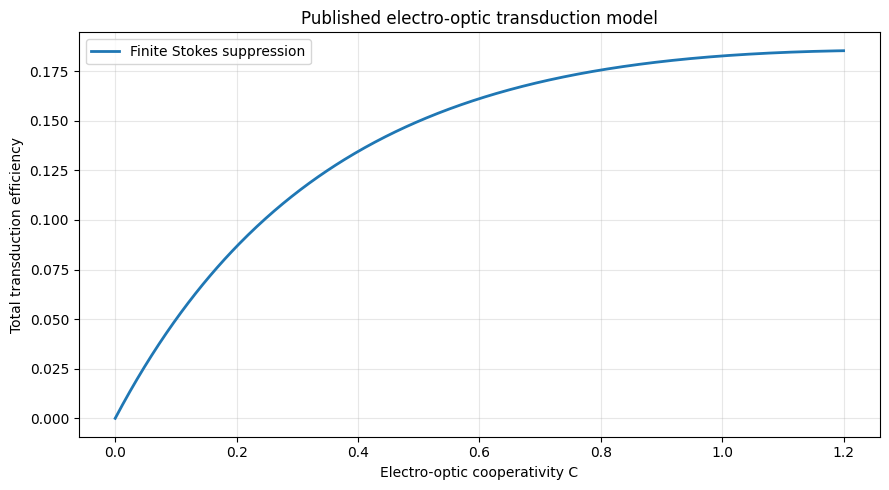

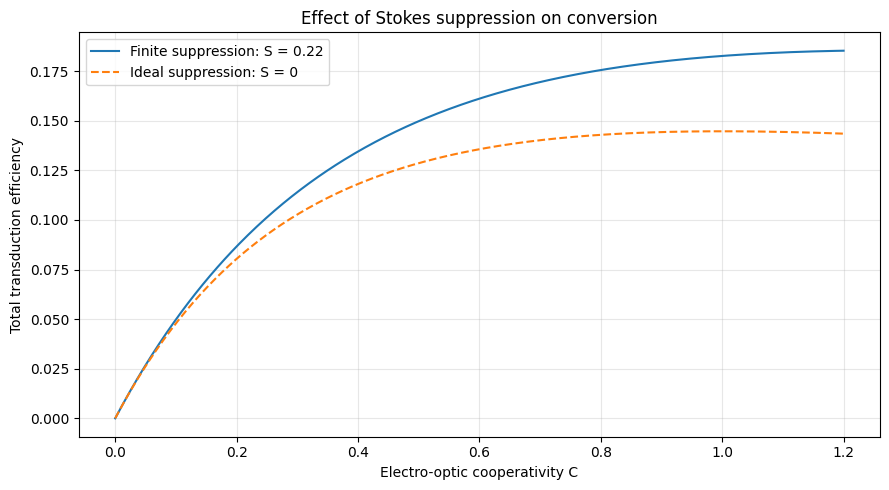

PASS: Efficiency remains finite and physical.
PASS: Zero cooperativity gives zero conversion efficiency.
PASS: Efficiency remains finite and within physical bounds.
PASS: Large suppression cooperativity approaches the ideal limit.

All numerical validation tests passed.


In [35]:
# Check whether the populations are approaching steady state.

nm = np.asarray(result_thermal.expect[0])
no = np.asarray(result_thermal.expect[1])

tail = max(10, len(tlist) // 10)

nm_change = abs(nm[-1] - nm[-tail])
no_change = abs(no[-1] - no[-tail])

print(f"Microwave population at final time: {nm[-1]:.6f}")
print(f"Optical population at final time:   {no[-1]:.6f}")
print(f"Microwave change over final interval: {nm_change:.6e}")
print(f"Optical change over final interval:   {no_change:.6e}")

def analytical_steady_state(G, kappa_m, kappa_o, nbar_m, nbar_o):
    """Steady-state occupations for resonant coupled bosonic modes."""

    if not all(np.isfinite(x) for x in
               [G, kappa_m, kappa_o, nbar_m, nbar_o]):
        raise ValueError("All parameters must be finite.")

    if G < 0 or kappa_m <= 0 or kappa_o <= 0:
        raise ValueError("G must be non-negative; decay rates positive.")

    if nbar_m < 0 or nbar_o < 0:
        raise ValueError("Thermal occupations must be non-negative.")

    if G == 0:
        return float(nbar_m), float(nbar_o)

    K = 4 * G**2 / (kappa_m + kappa_o)

    F = K * (nbar_m - nbar_o) / (
        1 + K * (1 / kappa_m + 1 / kappa_o)
    )

    nm_ss = nbar_m - F / kappa_m
    no_ss = nbar_o + F / kappa_o

    return float(nm_ss), float(no_ss)


nm_analytic, no_analytic = analytical_steady_state(
    G=G,
    kappa_m=kappa_m,
    kappa_o=kappa_o,
    nbar_m=nbar_m,
    nbar_o=nbar_o,
)

print(f"Analytical microwave occupation: {nm_analytic:.8f}")
print(f"Analytical optical occupation:   {no_analytic:.8f}")

t_long = np.linspace(0, 200, 3000)

result_long = qt.mesolve(
    H,
    rho0,
    t_long,
    c_ops_thermal,
    e_ops=[n_m, n_o],
    options={"store_states": False},
)

nm_num = float(result_long.expect[0][-1])
no_num = float(result_long.expect[1][-1])

print(f"Numerical microwave occupation: {nm_num:.8f}")
print(f"Numerical optical occupation:   {no_num:.8f}")

print(f"Microwave absolute difference: "
      f"{abs(nm_num - nm_analytic):.3e}")
print(f"Optical absolute difference:   "
      f"{abs(no_num - no_analytic):.3e}")

t_long = np.linspace(0, 200, 3000)

result_long = qt.mesolve(
    H,
    rho0,
    t_long,
    c_ops_thermal,
    e_ops=[n_m, n_o],
    options={"store_states": False},
)

nm_num = float(result_long.expect[0][-1])
no_num = float(result_long.expect[1][-1])

print(f"Numerical microwave occupation: {nm_num:.8f}")
print(f"Numerical optical occupation:   {no_num:.8f}")

print(f"Microwave absolute difference: "
      f"{abs(nm_num - nm_analytic):.3e}")
print(f"Optical absolute difference:   "
      f"{abs(no_num - no_analytic):.3e}")

plt.figure(figsize=(9, 5))

plt.plot(t_long, result_long.expect[0],
         label="Microwave: numerical")
plt.plot(t_long, result_long.expect[1],
         label="Optical: numerical")

plt.axhline(nm_analytic, linestyle="--",
            label="Microwave: analytical")
plt.axhline(no_analytic, linestyle="--",
            label="Optical: analytical")

plt.xlabel("Time (normalized units)")
plt.ylabel("Mean photon number")
plt.title("Steady-state validation of the two-mode model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

import numpy as np
import matplotlib.pyplot as plt



def published_transduction_efficiency(C, eta_e, eta_o, Lambda, C_J):
    # Convert cooperativity to a NumPy array.
    C = np.asarray(C, dtype=float)

    # Validate all inputs, including array inputs.
    scalar_values = [eta_e, eta_o, Lambda, C_J]

    if not np.all(np.isfinite(C)):
        raise ValueError("Cooperativity values must be finite.")

    if not all(np.isfinite(x) for x in scalar_values):
        raise ValueError("All scalar inputs must be finite.")

    if np.any(C < 0):
        raise ValueError("Cooperativity must be non-negative.")

    if C_J <= 0:
        raise ValueError("C_J must be positive.")

    if not all(0 <= x <= 1 for x in [eta_e, eta_o, Lambda]):
        raise ValueError("Efficiencies and Lambda must be between 0 and 1.")

    # Published analytical equation, including finite Stokes suppression.
    result = (
        eta_e * eta_o * Lambda**2
        * 4 * C * (1 + 1 / C_J)**2
        / (1 + C + 1 / C_J)**2
    )

    return result



# Experimental coupling parameters reported in the paper.
ETA_E = 0.41
ETA_O = 0.58
LAMBDA = 0.78

# The paper reports a suppression ratio of approximately 0.22.
# S = 1 / (1 + C_J), so C_J = 1/S - 1.
SUPPRESSION_RATIO = 0.22
C_J = 1 / SUPPRESSION_RATIO - 1

print(f"C_J: {C_J:.6f}")
print(
    "Efficiency at C=0.38:",
    f"{published_transduction_efficiency(0.38, ETA_E, ETA_O, LAMBDA, C_J):.6f}"
)

cooperativity = np.linspace(0, 1.2, 500)

efficiency_finite_suppression = np.array([
    published_transduction_efficiency(
        C, ETA_E, ETA_O, LAMBDA, C_J
    )
    for C in cooperativity
])

plt.figure(figsize=(9, 5))

plt.plot(
    cooperativity,
    efficiency_finite_suppression,
    label="Finite Stokes suppression",
    linewidth=2,
)

plt.xlabel("Electro-optic cooperativity C")
plt.ylabel("Total transduction efficiency")
plt.title("Published electro-optic transduction model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

efficiency_ideal = (
    ETA_O * ETA_E * LAMBDA**2
    * 4 * cooperativity
    / (1 + cooperativity)**2
)

plt.figure(figsize=(9, 5))

plt.plot(
    cooperativity,
    efficiency_finite_suppression,
    label="Finite suppression: S = 0.22",
)

plt.plot(
    cooperativity,
    efficiency_ideal,
    "--",
    label="Ideal suppression: S = 0",
)

plt.xlabel("Electro-optic cooperativity C")
plt.ylabel("Total transduction efficiency")
plt.title("Effect of Stokes suppression on conversion")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("PASS: Efficiency remains finite and physical.")


# Cell 19: Numerical validation tests

# Test 1: Zero cooperativity must give zero efficiency
eta_zero = published_transduction_efficiency(
    0.0, ETA_E, ETA_O, LAMBDA, C_J
)
assert np.isclose(eta_zero, 0.0, atol=1e-12)
print("PASS: Zero cooperativity gives zero conversion efficiency.")

# Test 2: Efficiency must remain finite and within physical bounds
C_test = np.linspace(0.0, 1.2, 200)
eta_test = published_transduction_efficiency(
    C_test, ETA_E, ETA_O, LAMBDA, C_J
)
assert np.all(np.isfinite(eta_test))
assert np.all(eta_test >= -1e-12)
assert np.all(eta_test <= 1.0 + 1e-12)
print("PASS: Efficiency remains finite and within physical bounds.")

# Test 3: Finite suppression approaches the ideal-suppression limit
C_check = 0.5
eta_finite = published_transduction_efficiency(
    C_check, ETA_E, ETA_O, LAMBDA, 1e6
)
eta_ideal = (
    ETA_E * ETA_O * LAMBDA**2
    * 4 * C_check / (1 + C_check)**2
)

assert np.isclose(eta_finite, eta_ideal, rtol=1e-5, atol=1e-10)
print("PASS: Large suppression cooperativity approaches the ideal limit.")

print("\nAll numerical validation tests passed.")

In [36]:


# Cell 20: Export transduction-efficiency sweep

import pandas as pd
from pathlib import Path

C_values = np.linspace(0.0, 1.2, 200)

eta_finite = published_transduction_efficiency(
    C_values, ETA_E, ETA_O, LAMBDA, C_J
)

eta_ideal = (
    ETA_E * ETA_O * LAMBDA**2
    * 4 * C_values / (1 + C_values)**2
)

results_df = pd.DataFrame({
    "cooperativity_C": C_values,
    "efficiency_finite_suppression": eta_finite,
    "efficiency_ideal_suppression": eta_ideal
})

output_file = Path("transduction_efficiency_results.csv")
results_df.to_csv(output_file, index=False)

print(f"Saved: {output_file}")
print(f"Rows: {len(results_df)}")
print(results_df.head())

Saved: transduction_efficiency_results.csv
Rows: 200
   cooperativity_C  efficiency_finite_suppression  \
0         0.000000                       0.000000   
1         0.006030                       0.003457   
2         0.012060                       0.006850   
3         0.018090                       0.010180   
4         0.024121                       0.013448   

   efficiency_ideal_suppression  
0                      0.000000  
1                      0.003448  
2                      0.006814  
3                      0.010100  
4                      0.013309  


In [37]:

from google.colab import files

files.download("transduction_efficiency_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

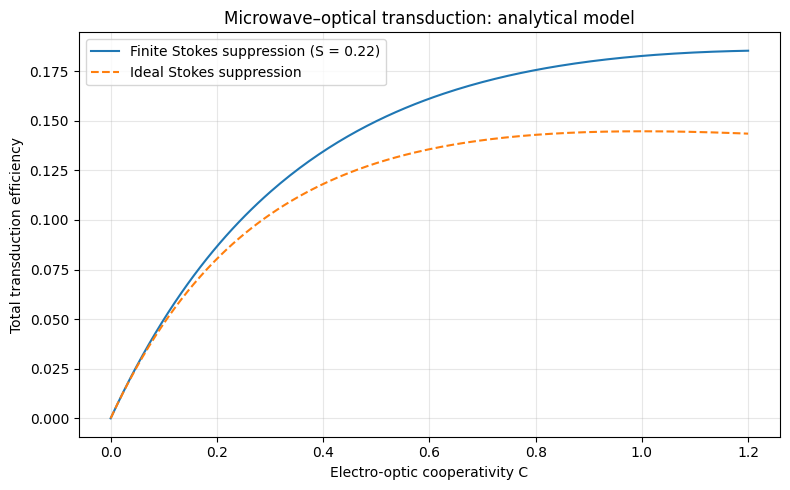

Saved: transduction_efficiency_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

# Cell 22: Save the published-model comparison plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    C_values, eta_finite,
    label="Finite Stokes suppression (S = 0.22)"
)
plt.plot(
    C_values, eta_ideal,
    "--",
    label="Ideal Stokes suppression"
)

plt.xlabel("Electro-optic cooperativity C")
plt.ylabel("Total transduction efficiency")
plt.title("Microwave–optical transduction: analytical model")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_file = "transduction_efficiency_comparison.png"
plt.savefig(plot_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {plot_file}")

files.download("transduction_efficiency_comparison.png")